# Biblioteki

In [ ]:
#biblioteki
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras import layers, Model
from torch.utils.data import DataLoader, TensorDataset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import transforms
from skimage.io import imsave
from scipy.ndimage import label
from torchvision import models
from pytorch_grad_cam import GradCAM,GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image, preprocess_image
import PIL

# Wczytanie danych

In [ ]:
# Tu są zapisane wszystkie modele oraz dane testowe
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data/

BA_173620.jpg	EO_136177.jpg	IG_265929.jpg	MO_107817.jpg
BA_190505.jpg	EO_150361.jpg	LY_107981.jpg	MO_14768.jpg
BNE_109895.jpg	ERB_112663.jpg	LY_131013.jpg	PLATELET_114385.jpg
BNE_175617.jpg	ERB_113277.jpg	MMY_122535.jpg	PLATELET_120145.jpg


In [ ]:
!ls /content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/classification_models

Model1_whole_pic.pth  Model2_cropped_photos.pth  Model_3_cell_metrics.pth


# Testowanie modelów bez cech morfologicznych.

## Segmentacja komórek krwi

In [ ]:
!ls /content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/segmentation_model/

model_v2_1.pth	results7.png  test_results.png


In [ ]:
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # Enkoder
        self.enc_conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.enc_conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.enc_conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # Dekoder
        self.dec_conv1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec_conv2 = nn.ConvTranspose2d(64, 16, kernel_size=2, stride=2)
        self.dec_conv3 = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        x1 = F.relu(self.enc_conv1(x))
        x1_pooled = self.pool(x1)

        x2 = F.relu(self.enc_conv2(x1_pooled))
        x2_pooled = self.pool(x2)

        x3 = F.relu(self.enc_conv3(x2_pooled))

        x4 = F.relu(self.dec_conv1(x3))
        x4 = torch.cat([x4, x2], dim=1)

        x5 = F.relu(self.dec_conv2(x4))
        x5 = torch.cat([x5, x1], dim=1)

        output = torch.sigmoid(self.dec_conv3(x5))

        return output

In [ ]:
image_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data/"
output_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/results_segmentacja"
images = []
image_filenames = []
for img_name in os.listdir(image_folder):
    if img_name.endswith(('.png', '.jpg', '.jpeg', '.bmp')):  # Sprawdzenie formatu obrazu
        image_file_path = os.path.join(image_folder, img_name)
        image = Image.open(image_file_path).resize((368, 368))  # Rozmiar do 368x368
        images.append(image)
        image_filenames.append(img_name)

# Sprawdzenie liczby wczytanych obrazów
print(f"Liczba wczytanych obrazów: {len(images)}")

test_images = np.array([np.array(img) for img in images]).astype(np.float32) / 255.0
test_images = np.transpose(test_images, (0, 3, 1, 2))
test_images = torch.tensor(test_images, dtype=torch.float32)
test_loader = DataLoader(test_images, batch_size=16, shuffle=False)

Liczba wczytanych obrazów: 17


<ipython-input-21-94354d1ac74e>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  seg_model = torch.load("/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/segmentation_mode

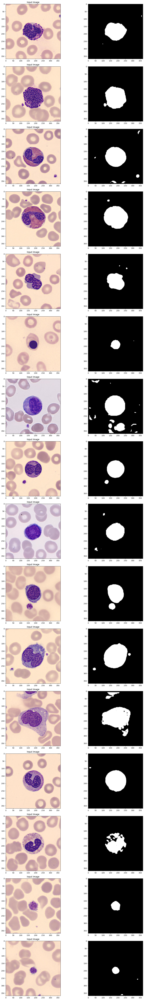

In [ ]:
seg_model = torch.load("/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/segmentation_model/model_v2_1.pth")
seg_model.eval()

def segment_blood_cells(input_image, segmentation_model):
    # Przygotowanie obrazu wejściowego
    obraz = np.array([np.array(input_image)]).astype(np.float32) / 255.0
    obraz_transpose = np.transpose(obraz, (0, 3, 1, 2))
    obraz_tensor = torch.tensor(obraz_transpose, dtype=torch.float32)

    # Przewidywanie maski
    with torch.no_grad():  # Dezaktywacja gradientów
        maska = seg_model(obraz_tensor)  # Przepuszczenie przez model
        maska = torch.sigmoid(maska)
    # Przekształcenie wyniku na numpy i usunięcie wymiaru wsadowego
    maska = maska.squeeze().detach().cpu().numpy()

    return maska

# ======== Ocena na zbiorze testowym (bez masek) ========
predictions, inputs_list = [], []

with torch.no_grad():
    for inputs in test_loader:

        outputs = seg_model(inputs)

        predictions.append(outputs)
        inputs_list.append(inputs)

# Wizualizacja wyników
num_samples = 16 # Liczba przykładów do wizualizacji
fig, axes = plt.subplots(num_samples, 2, figsize=(15, 5 * num_samples))

for i in range(num_samples):
    sample_input = inputs_list[0][i].cpu()
    sample_prediction = torch.round(predictions[0][i].cpu())

    axes[i, 0].imshow(sample_input.permute(1, 2, 0).numpy())
    axes[i, 0].set_title('Input Image')

    axes[i, 1].imshow(sample_prediction[0].numpy(), cmap='gray')
    original_image_name = image_filenames[i]  # Odczytanie nazwy obrazu z wcześniej zapisanej listy
    image_name_without_extension = os.path.splitext(original_image_name)[0]  # Usuń rozszerzenie

    # Zapisanie maski z nazwą oryginalnego obrazu
    mask_filename = f"{output_folder}/predicted_mask_{image_name_without_extension}.png"

    # Normalizacja i konwersja do uint8
    mask_image = (sample_prediction[0].numpy() * 255).astype(np.uint8)
    imsave(mask_filename, mask_image)

plt.tight_layout()
plt.savefig('test_results_without_masks.png', dpi=300, bbox_inches='tight')
plt.show()


## Przygotowanie wyników z modelu segmentacji do modelu klasyfikacji.



In [ ]:
#upewnij się, że wszystkie obrazy są w dobrym miejscu!:)
!ls "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/results_segmentacja"

predicted_mask_BA_173620.png   predicted_mask_ERB_112663.png  predicted_mask_MO_107817.png
predicted_mask_BA_190505.png   predicted_mask_ERB_113277.png  predicted_mask_MO_14768.png
predicted_mask_BNE_109895.png  predicted_mask_IG_265929.png   predicted_mask_PLATELET_114385.png
predicted_mask_BNE_175617.png  predicted_mask_LY_107981.png   predicted_mask_PLATELET_120145.png
predicted_mask_EO_136177.png   predicted_mask_LY_131013.png
predicted_mask_EO_150361.png   predicted_mask_MMY_122535.png


In [ ]:
#jeśli tak to możesz wykonać filtrowanie zostawiając tylko największy obiekt
# Ścieżka do folderu z obrazami
folder_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/results_segmentacja"
output_folder_clean = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/do_klasyfikacji"
# Iteracja po wszystkich plikach w folderze
for filename in os.listdir(folder_path):
    # Sprawdź, czy plik jest obrazem (np. pliki .png)
    if filename.endswith('.png'):
        # Wczytanie obrazu
        image_path = os.path.join(folder_path, filename)
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        # Sprawdzenie, czy obraz został poprawnie wczytany
        if image is not None:
            # Binarne progowanie obrazu
            _, binary_image = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)

            # Etykietowanie obiektów
            labeled_image, num_labels = label(binary_image)

            # Obliczanie rozmiarów obiektów
            sizes = [np.sum(labeled_image == i) for i in range(1, num_labels + 1)]
            max_size_label = np.argmax(sizes) + 1  # Etykieta największego obiektu

            # Tworzenie maski dla największego obiektu
            largest_object_mask = np.uint8(labeled_image == max_size_label) * 255

            # Uzupełnianie dziur w masce
            # Wyszukiwanie konturów
            contours, _ = cv2.findContours(largest_object_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            # Rysowanie konturów na pustym obrazie (do wypełnienia)
            filled_mask = np.zeros_like(largest_object_mask)

            # Rysowanie wypełnionych konturów na nowej masce
            cv2.drawContours(filled_mask, contours, -1, (255), thickness=cv2.FILLED)

            # Zapisz lub wyświetl wynik
            output_path = os.path.join(output_folder_clean, f'largest_filled_{filename}')
            cv2.imwrite(output_path, filled_mask)
            print(f'Zapisano wynik dla: {filename}')
        else:
            print(f'Błąd wczytywania obrazu: {filename}')

Zapisano wynik dla: predicted_mask_MMY_122535.png
Zapisano wynik dla: predicted_mask_BNE_175617.png
Zapisano wynik dla: predicted_mask_IG_265929.png
Zapisano wynik dla: predicted_mask_PLATELET_114385.png
Zapisano wynik dla: predicted_mask_BA_173620.png
Zapisano wynik dla: predicted_mask_LY_131013.png
Zapisano wynik dla: predicted_mask_MO_107817.png
Zapisano wynik dla: predicted_mask_ERB_112663.png
Zapisano wynik dla: predicted_mask_BA_190505.png
Zapisano wynik dla: predicted_mask_EO_136177.png
Zapisano wynik dla: predicted_mask_ERB_113277.png
Zapisano wynik dla: predicted_mask_EO_150361.png
Zapisano wynik dla: predicted_mask_LY_107981.png
Zapisano wynik dla: predicted_mask_MO_14768.png
Zapisano wynik dla: predicted_mask_BNE_109895.png
Zapisano wynik dla: predicted_mask_PLATELET_120145.png


## Klasyfikacja komórek krwi

In [ ]:
# ------ Funkcja do wyodrębniania celu ze zdjęć za pomocą maski ---------
import cv2
def apply_mask(image_path, mask_path):

  # Wczytanie obrazu i maski
  image = cv2.imread(image_path)
  mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Odczyt maski w odcieniach szarości

  # Jeśli maska i obraz mają różne rozmiary, dostosuj maskę do rozmiaru obrazu
  if image.shape[:2] != mask.shape[:2]:
    mask = cv2.resize(mask, (image.shape[1], image.shape[0]))

  # Stworzenie obrazu z szarym tłem
  gray_background = np.full_like(image, (128, 128, 128))  # Szare tło (R=128, G=128, B=128)
  # Utwórz maskę binarną, która zawiera tylko wartości 0 lub 255
  _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

  # Stosowanie maski do obrazu: zachowanie tylko obszaru maski, reszta na szaro
  result = np.where(binary_mask[..., None] == 255, image, gray_background)
  return result


In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc1 = nn.Linear(128 * 45 * 45, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)

        out = out.view(out.size(0), -1)

        out = self.dropout(out)
        out = self.fc1(out)
        out = nn.ReLU()(out)
        out = self.fc2(out)

        return out

In [ ]:
def classify_blood_cells(classification_model, image):
    # Model ma być w trybie ewaluacyjnym
    classification_model.eval()

    # Transformacja obrazu
    preprocess = transforms.Compose([
        transforms.Resize((360, 363)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    input_tensor = preprocess(image).unsqueeze(0)  # Dodanie wymiaru batch

    # Przewidywanie klasy
    with torch.no_grad():
        outputs = classification_model(input_tensor)  # Przepuszczenie przez model
        _, predicted_class = torch.max(outputs, 1)   # Znalezienie klasy o najwyższym prawdopodobieństwie

    # Mapowanie indeksów na nazwy klas
    class_labels = ["basophil", "eosinophil", "erythroblast", "ig", "lymphocyte", "monocyte", "neutrophil", "platelet"]

    class_name = class_labels[predicted_class.item()]

    return class_name

### wersja dla pojedynczego obrazu

In [ ]:
mask = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/do_klasyfikacji/largest_filled_predicted_mask_PLATELET_120145.png"
classification_model_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/classification_models/Model2_cropped_photos.pth"
test_image_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data/PLATELET_120145.jpg"

In [ ]:
def cooperating_models(classification_model_path, test_image_path, mask):
    # Wczytanie modelu klasyfikacji
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    classification_model = ConvNet(num_classes=10)
    classification_model.load_state_dict(torch.load(classification_model_path, map_location=device, weights_only=True), strict=False)

    image = apply_mask(test_image_path, mask)
    masked_image_pil = Image.fromarray(image)
    # Klasyfikacja komórek krwi
    class_name = classify_blood_cells(classification_model, masked_image_pil)
    print("Predicted class name: ", class_name)


In [ ]:
cooperating_models(classification_model_path, test_image_path, mask)

Predicted class name:  platelet


### wersja dla wielu obrazów

Predicted class name:  eosinophil


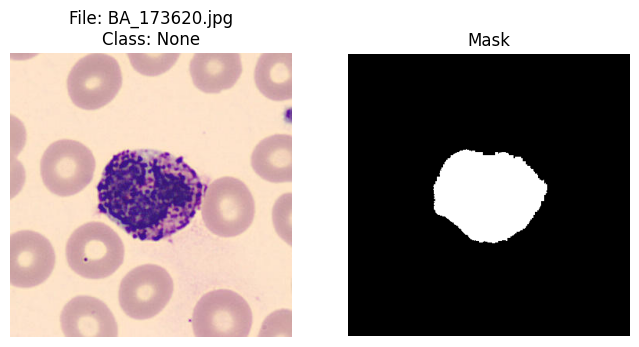

Predicted class name:  eosinophil


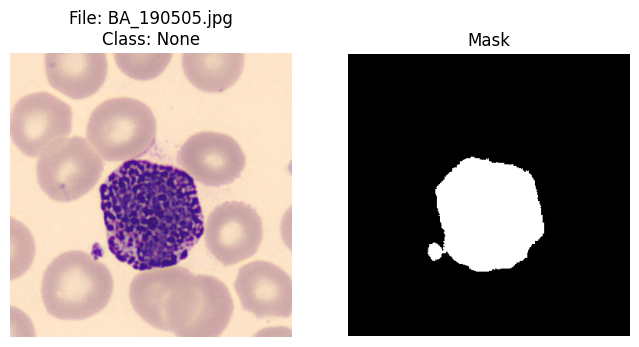

Predicted class name:  eosinophil


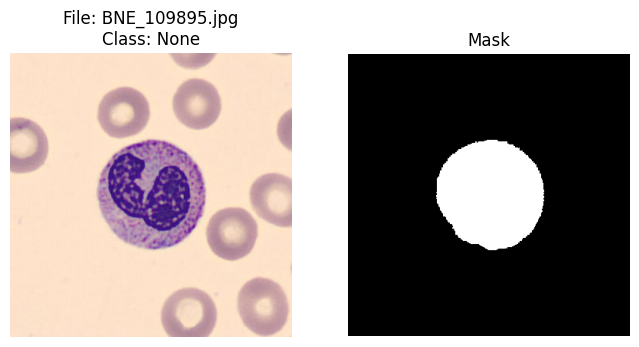

Predicted class name:  eosinophil


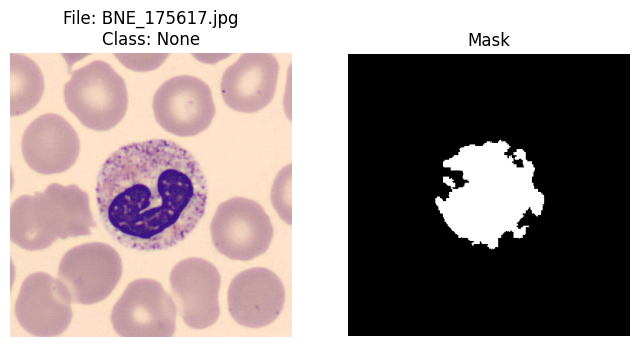

Predicted class name:  eosinophil


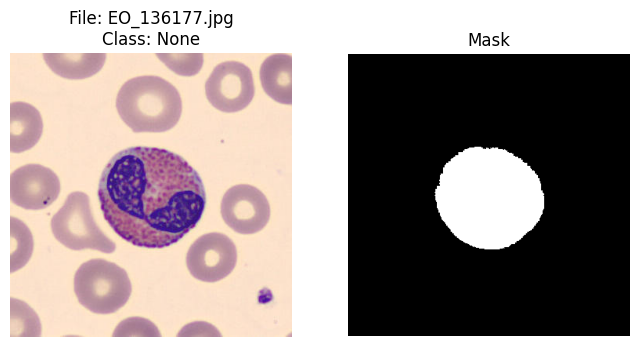

Predicted class name:  eosinophil


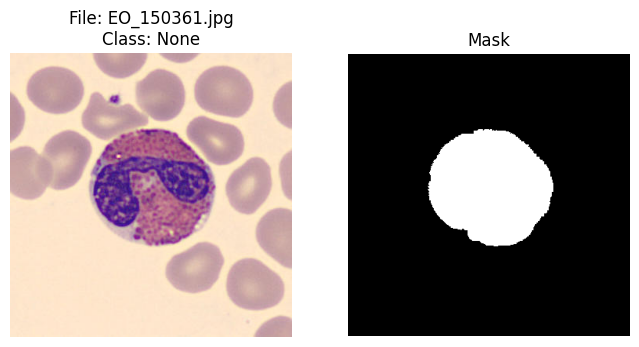

Predicted class name:  eosinophil


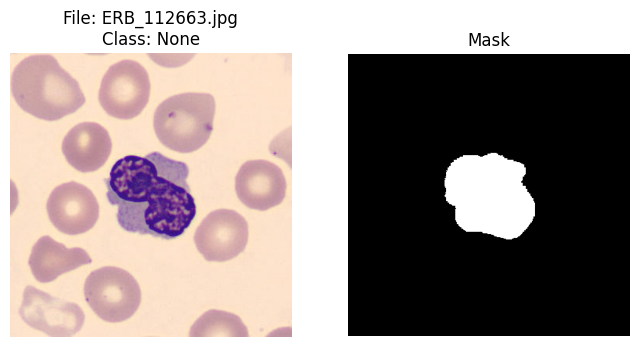

Predicted class name:  platelet


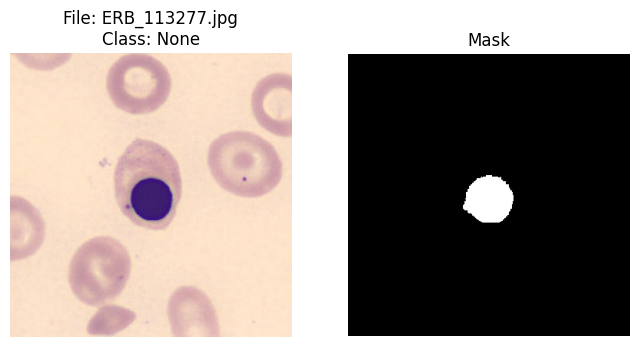

Predicted class name:  eosinophil


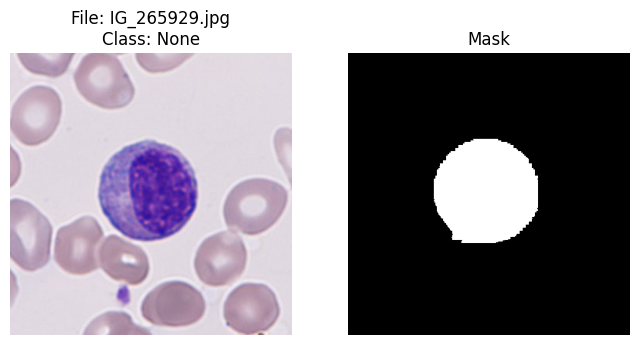

Predicted class name:  eosinophil


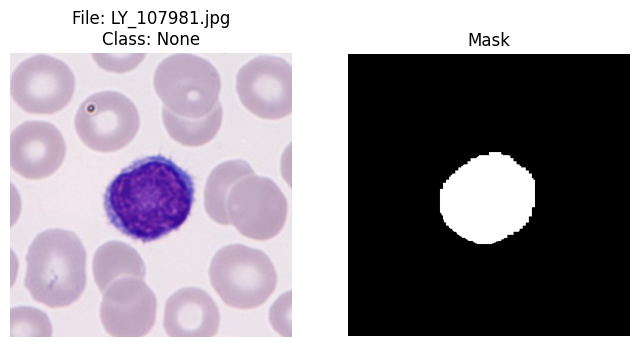

Predicted class name:  eosinophil


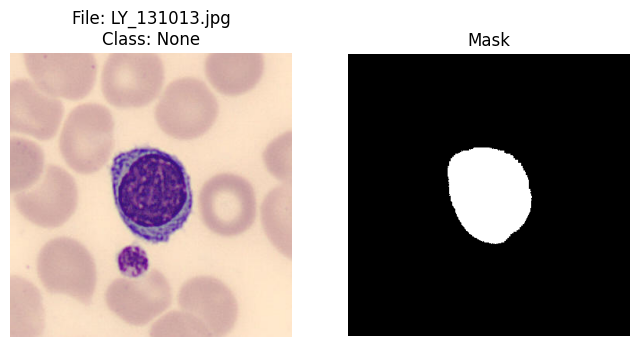

Predicted class name:  eosinophil


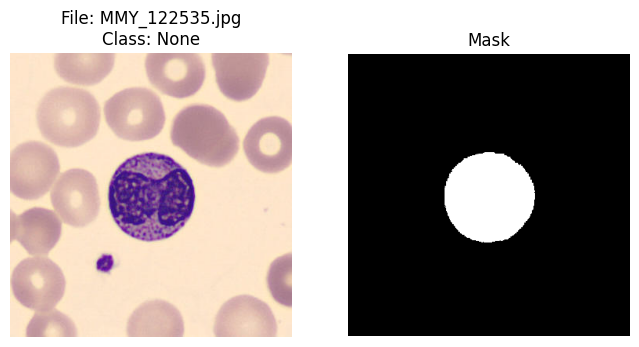

Predicted class name:  eosinophil


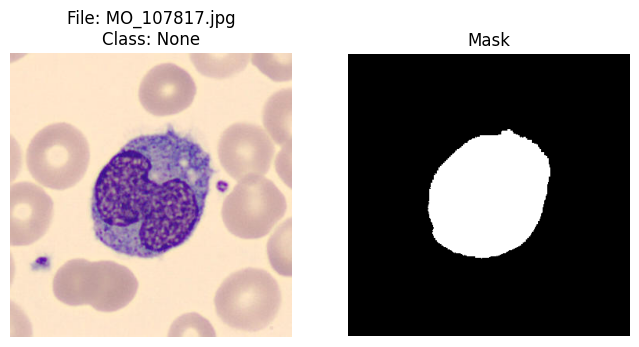

Predicted class name:  eosinophil


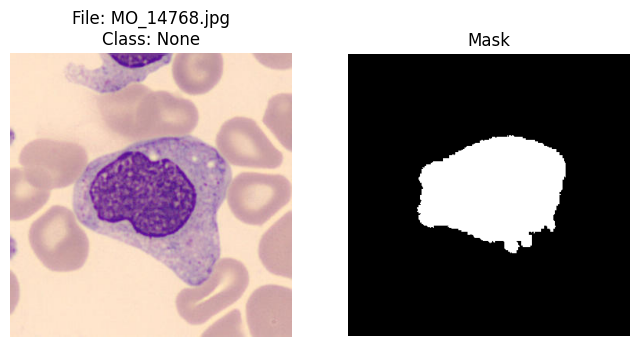

Predicted class name:  platelet


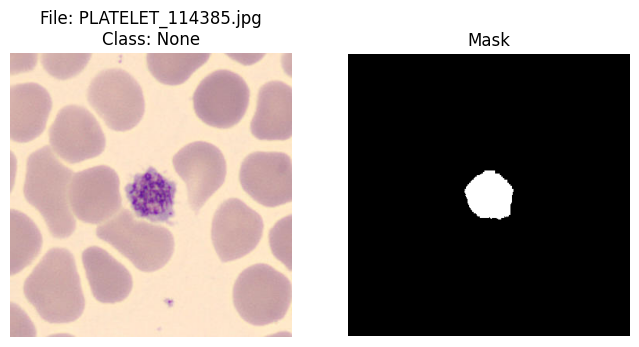

Predicted class name:  platelet


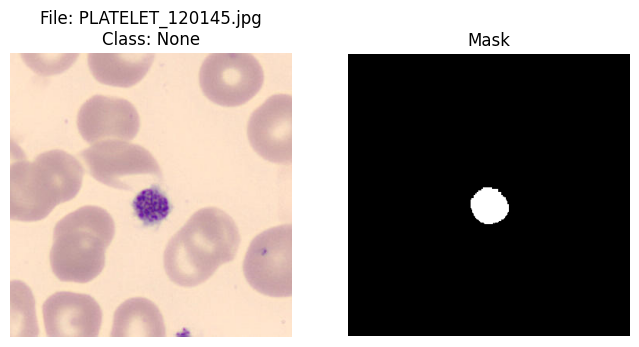

In [ ]:
def display_image_with_class(image_path, mask_path, predicted_class):
    image = cv2.imread(image_file_path)
    mask = cv2.imread(mask_file_path, cv2.IMREAD_GRAYSCALE)
    plt.figure(figsize=(8, 8))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"File: {os.path.basename(image_file_path)}\nClass: {predicted_class}")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask")
    plt.axis('off')

    plt.show()


mask_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/do_klasyfikacji"
classification_model_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/classification_models/Model2_cropped_photos.pth"
test_image_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data"

mask_files = sorted(os.listdir(mask_folder))
test_image_files = sorted(os.listdir(test_image_path))

for mask_file, image_file in zip(mask_files, test_image_files):
    mask_file_path = os.path.join(mask_folder, mask_file)
    image_file_path = os.path.join(test_image_path, image_file)
    predicted_class = cooperating_models(classification_model_path, image_file_path, mask_file_path)
    display_image_with_class(image_file_path, mask_file_path, predicted_class)

## Class activation mapping

Kod został opracowany na podstawie tej strony -> https://www.pinecone.io/learn/class-activation-maps/#Understanding-Grad-CAM++


Ze względu na to, że dla zdjęć w naszym zbiorze testowym większość błędnych klasyfikacji to były eozynofile to pod obserwację bierzemy właśnie tę klasę.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classification_model = ConvNet(num_classes=10)
classification_model.load_state_dict(torch.load(classification_model_path, map_location=device, weights_only=True), strict=False)
classification_model.eval()
targets = [ClassifierOutputTarget(1)] #monitorowanie klasy numer 1
target_layers = [classification_model.layer3]
cam = GradCAM(model=classification_model, target_layers=target_layers) # use GradCamPlusPlus class

In [ ]:
# struktura funkcji GradCAM
def result_CAM(image_path_cam, cam, filename):
  img = np.array(PIL.Image.open(image_path_cam))
  img = cv2.resize(img, (360, 363))
  img = np.float32(img) / 255
  input_tensor = preprocess_image(img)

  grayscale_cams = cam(input_tensor=input_tensor, targets=targets)
  cam_image = show_cam_on_image(img, grayscale_cams[0, :], use_rgb=True)

  cam = np.uint8(255*grayscale_cams[0, :])
  cam = cv2.merge([cam, cam, cam])

  images = np.hstack((np.uint8(255*img), cam_image))
  plt.figure(figsize=(10, 5))
  plt.imshow(images)
  plt.title(f"Nazwa zdjęcia: {filename}", fontsize=14)
  plt.axis('off')  # Ukrycie osi
  plt.show()

#### Wersja dla obrazów z tłem.

##### Wersja dla wielu zdjęć.

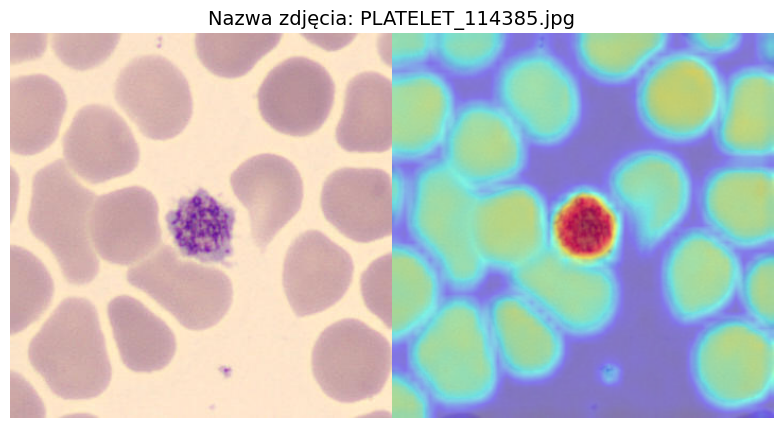

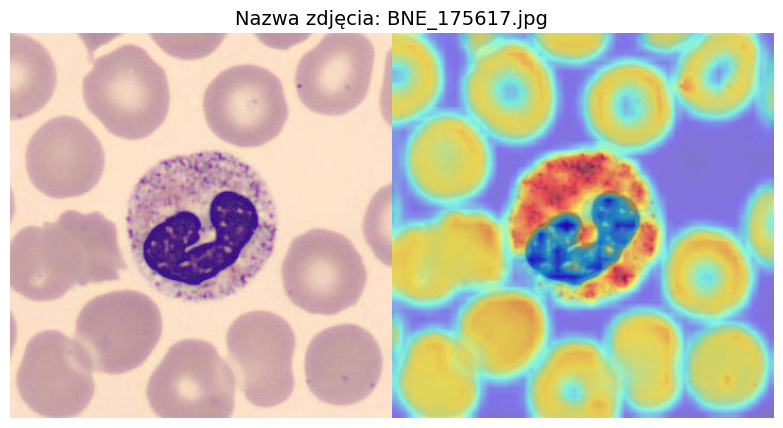

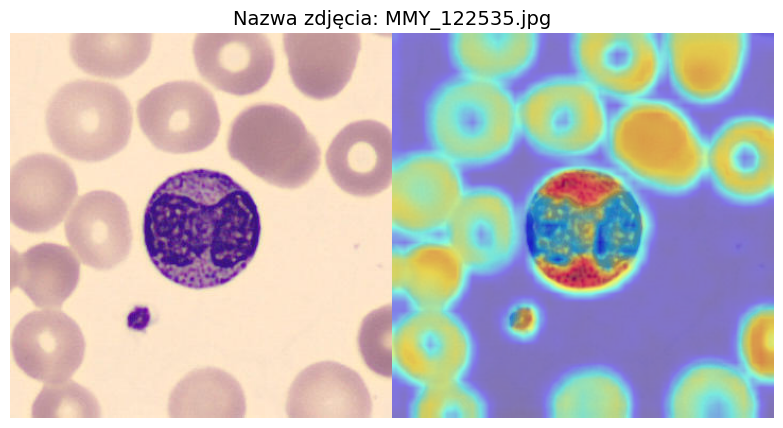

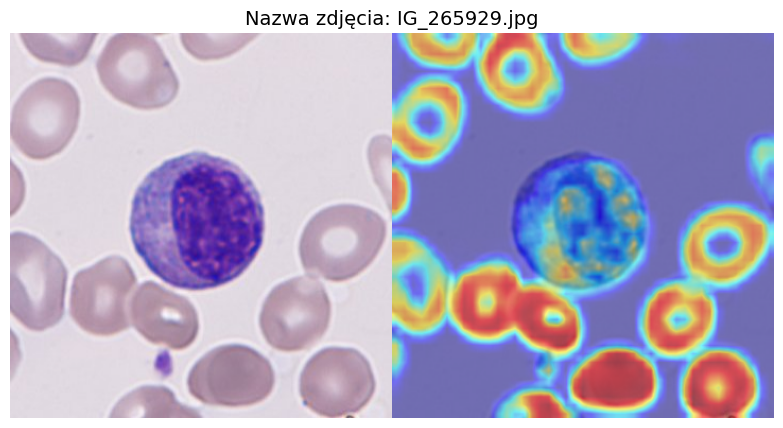

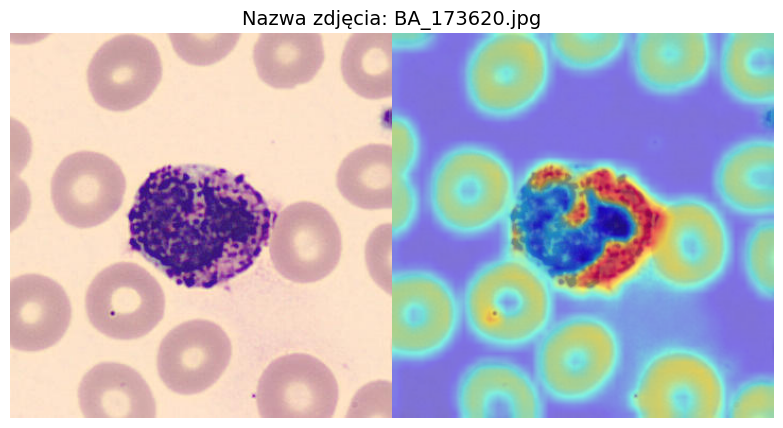

...

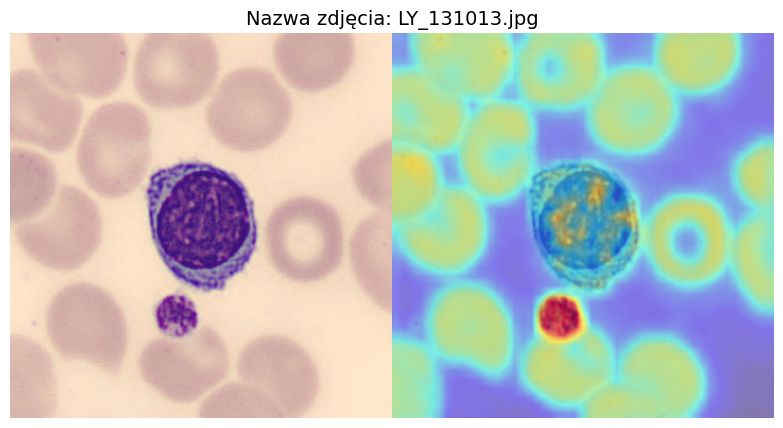

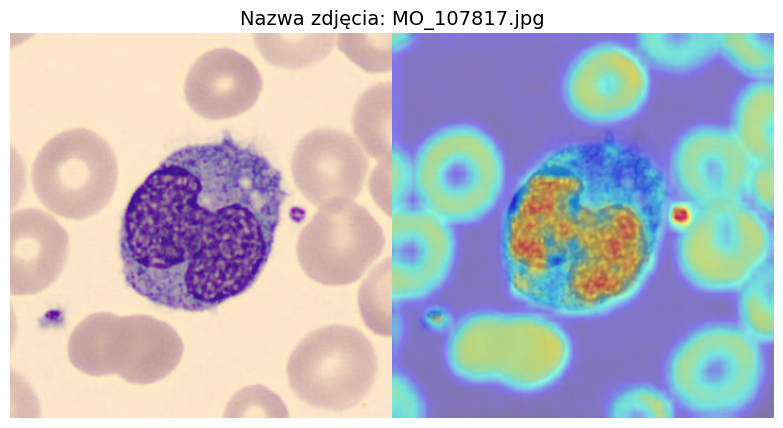

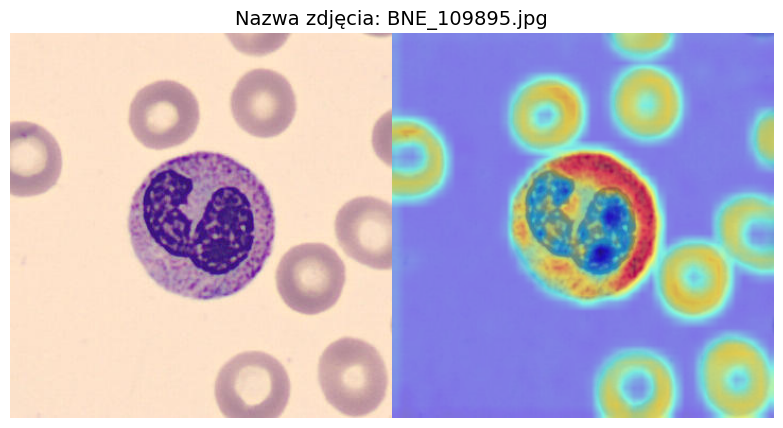

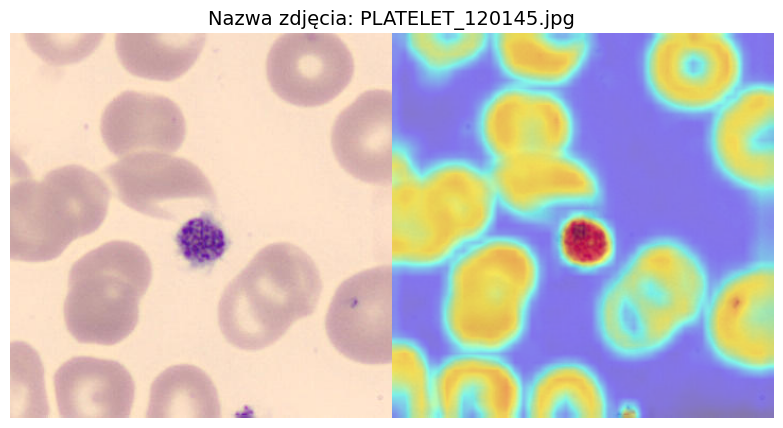

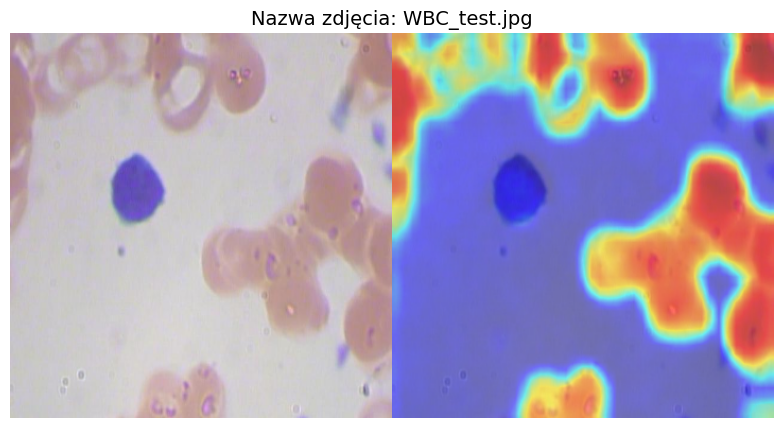

In [ ]:
folder_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data"


for filename in os.listdir(folder_path):
    if filename.endswith('.jpg'):
        image_path = os.path.join(folder_path, filename)
        result_CAM(image_path, cam, filename)

##### Wersja dla jednego zdjęcia

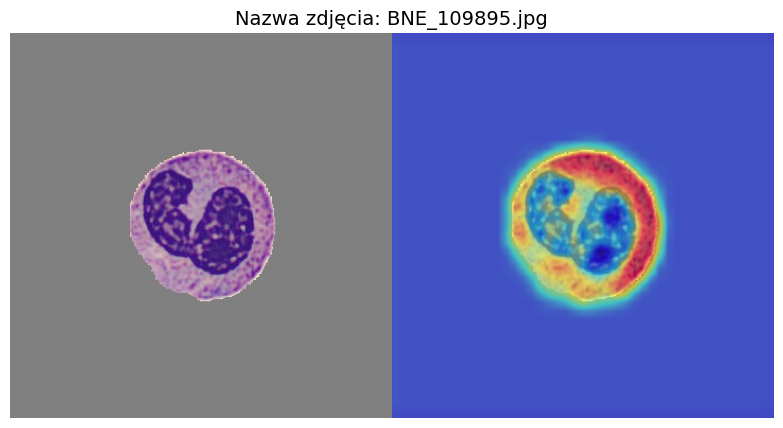

In [ ]:
image_path = '/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data_without_background/BNE_109895.jpg'
if image_path.endswith('.jpg'):
    result_CAM(image_path, cam, os.path.basename(image_path))

#### Wersja dla obrazów bez tła.

In [ ]:
mask_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/do_klasyfikacji"
test_image_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data"
output_folder = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data_without_background"

def apply_mask(image_path, mask_path):
    # Wczytanie obrazu i maski
    image = cv2.imread(image_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Odczyt maski w odcieniach szarości

    # Jeśli maska i obraz mają różne rozmiary, dostosuj maskę do rozmiaru obrazu
    if image.shape[:2] != mask.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]))

    # Stworzenie obrazu z szarym tłem
    gray_background = np.full_like(image, (128, 128, 128))  # Szare tło (R=128, G=128, B=128)

    # Utwórz maskę binarną, która zawiera tylko wartości 0 lub 255
    _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    # Stosowanie maski do obrazu: zachowanie tylko obszaru maski, reszta na szaro
    result = np.where(binary_mask[..., None] == 255, image, gray_background)
    return result

# Przechodzenie po wszystkich obrazach w folderze testowym
for image_name in os.listdir(test_image_folder):
    image_path = os.path.join(test_image_folder, image_name)
    mask_name = f"largest_filled_predicted_mask_{os.path.splitext(image_name)[0]}.png"
    mask_path = os.path.join(mask_folder, mask_name)
    if os.path.isfile(image_path) and os.path.isfile(mask_path):
        # Zastosowanie maski
        result_image = apply_mask(image_path, mask_path)

        # Zapis obrazu wynikowego
        output_path = os.path.join(output_folder, image_name)
        cv2.imwrite(output_path, result_image)

print("Przetwarzanie zakończone. Wyniki zapisano w:", output_folder)

Przetwarzanie zakończone. Wyniki zapisano w: /content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data_without_background


##### Wersja dla wielu obrazów

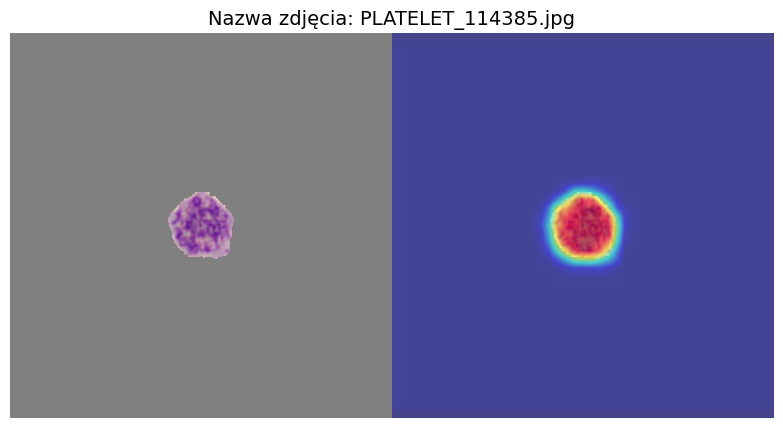

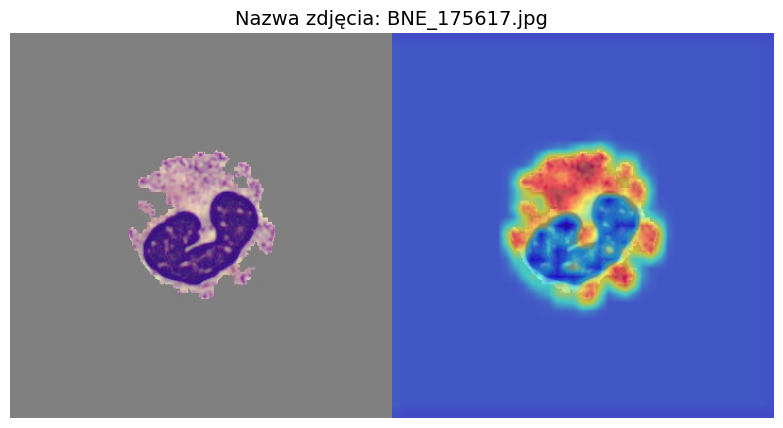

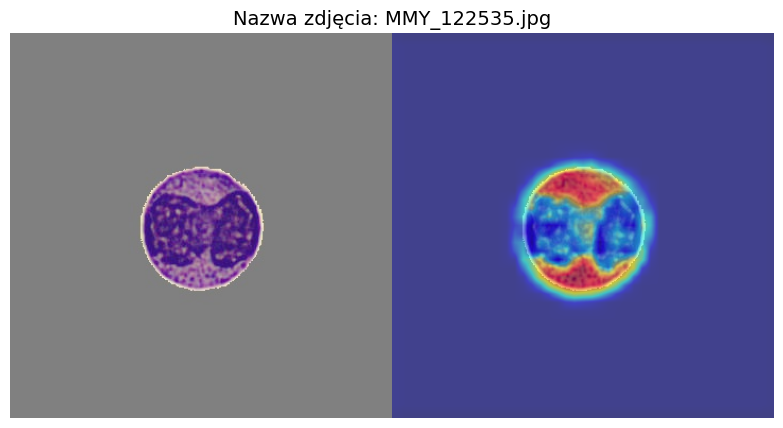

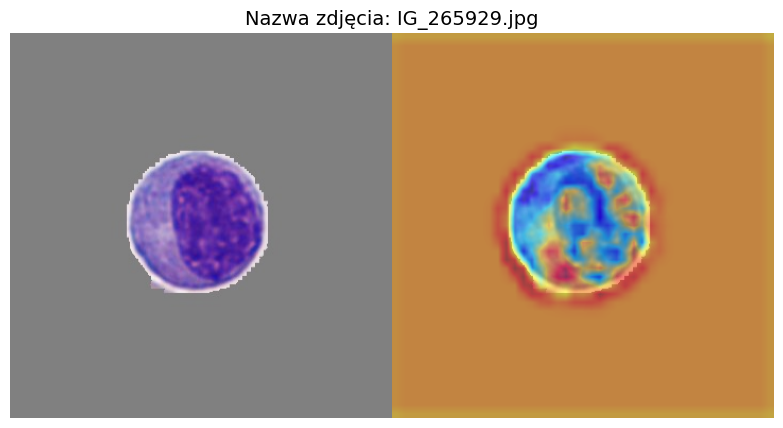

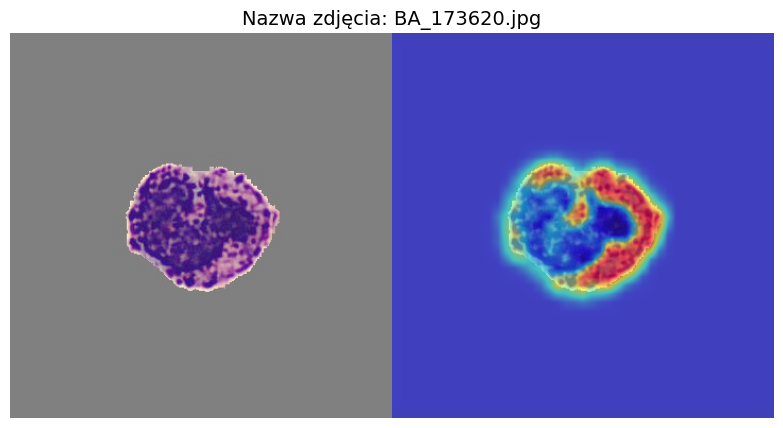

...

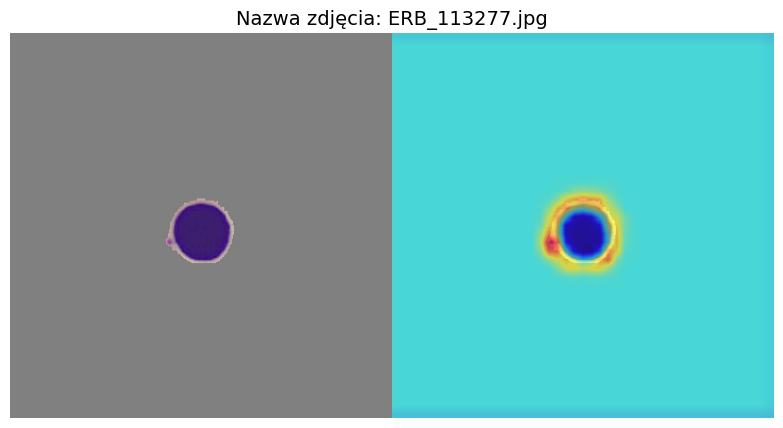

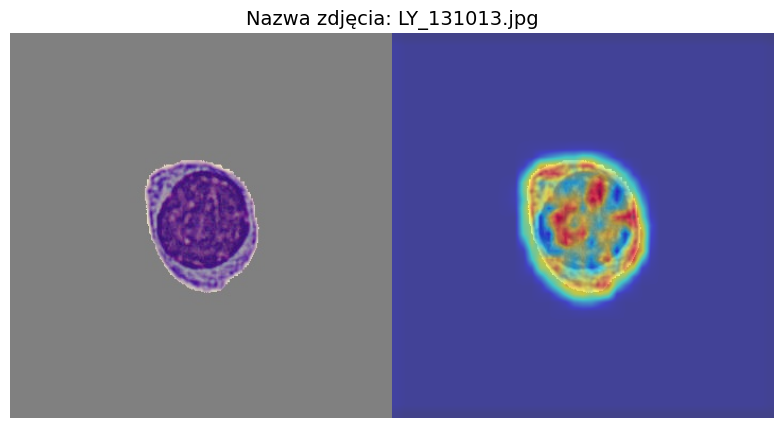

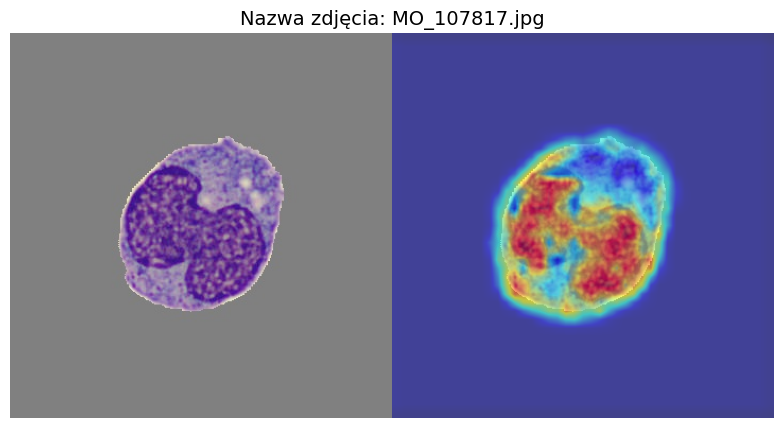

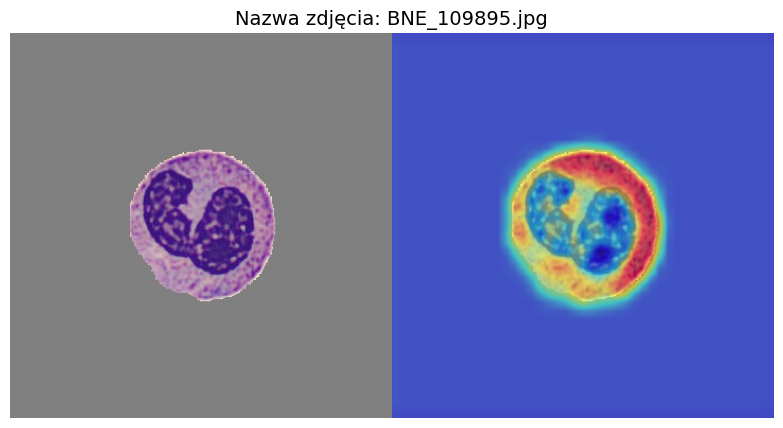

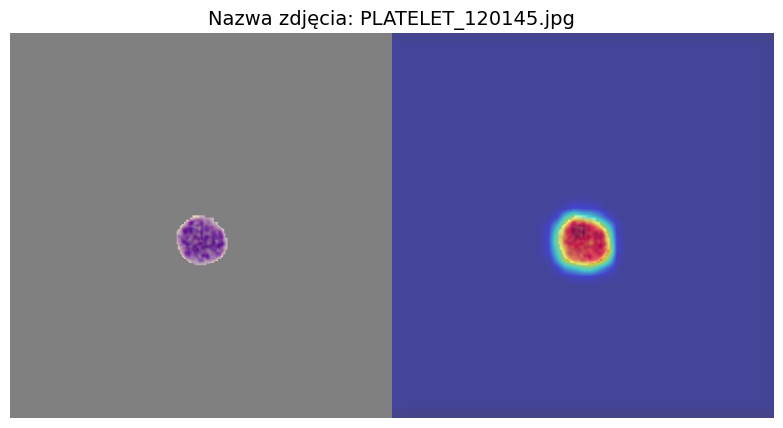

In [ ]:
folder_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data_without_background"


for filename in os.listdir(folder_path):
    if filename.endswith('.jpg'):
        image_path = os.path.join(folder_path, filename)
        result_CAM(image_path, cam, filename)

##### Wersja dla jednego obrazu

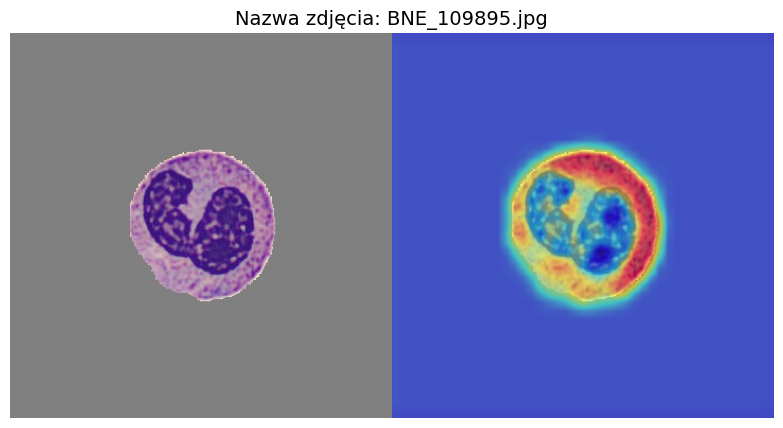

In [ ]:
image_path = '/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data_without_background/BNE_109895.jpg'
if image_path.endswith('.jpg'):
    result_CAM(image_path, cam, os.path.basename(image_path))

# Testowanie modelu 3 - na croppowanych zdjęciach razem z cechami morfologicznymi

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops
from torch.utils.data import Dataset, DataLoader

In [ ]:
# Obliczenie cech morfologicznych:
def calculate_morphological_features(classified_image, bounding_box):
    x_min, y_min, x_max, y_max = bounding_box
    cropped_cell = image[y_min:y_max, x_min:x_max]

    _, binary_cell = cv2.threshold(cropped_cell, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(binary_cell, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        contour = contours[0]

        area = cv2.contourArea(contour)
        perimeter = cv2.arcLength(contour, True)
        _, _, w, h = cv2.boundingRect(contour)


        glcm = graycomatrix(cropped_cell, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

        return [
            area, perimeter, contrast, homogeneity
        ]
    return [0] * 4

In [ ]:
class HybridModel(nn.Module):
    def __init__(self, num_classes=10):
        super(HybridModel, self).__init__()

        # Część konwolucyjna
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),  # Warstwa konwolucyjna 1
            nn.BatchNorm2d(32),  # Normalizacja wsadowa
            nn.ReLU(),  # Funkcja aktywacji
            nn.MaxPool2d(kernel_size=2, stride=2),  # MaxPooling

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),  # Warstwa konwolucyjna 2
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),  # Warstwa konwolucyjna 3
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2) # MaxPooling
        )

        # Część dla cech morfologicznych
        self.morph_fc = nn.Sequential(
            nn.Linear(4, 64),  # Warstwa liniowa (4 wejścia -> 64 wyjścia)
            nn.BatchNorm1d(64),  # Normalizacja
            nn.ReLU(),  # Funkcja aktywacji
            nn.Dropout(0.5)  # Dropout
        )

        # Końcowa sieć łącząca cechy obrazu i cechy morfologiczne
        self.fc_combined = nn.Sequential(
            nn.Linear(128 * 45 * 45 + 64, 512),  # Warstwa liniowa łącząca (cechy obrazu + morfologiczne)
            nn.BatchNorm1d(512),  # Normalizacja
            nn.ReLU(),  # Funkcja aktywacji
            nn.Dropout(0.5),  # Dropout
            nn.Linear(512, num_classes)  # Warstwa końcowa (512 -> liczba klas)
        )

    def forward(self, image, morph_features):
        # Ekstrakcja cech z obrazów za pomocą części konwolucyjnej
        image_features = self.cnn(image)
        image_features = image_features.view(image_features.size(0), -1)  # Spłaszczenie cech obrazu

        # Ekstrakcja cech morfologicznych
        morph_features = self.morph_fc(morph_features)

        # Połączenie cech obrazu i morfologicznych
        combined_features = torch.cat((image_features, morph_features), dim=1)

        # Przetworzenie połączonych cech przez końcowe warstwy
        out = self.fc_combined(combined_features)

        return out


In [ ]:
# Funkcja do klasyfikacji zdjęć:

def classify_blood_cells_hybrid(classification_model, image_path):
    # Model ma być w trybie ewaluacyjnym
    classification_model.eval()

    preprocess = transforms.Compose([
        transforms.Resize((360, 363)),  # Dostosowanie rozmiaru
        transforms.ToTensor(),         # Konwersja do tensora
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
    ])
    image = preprocess(image_path).unsqueeze(0)  # Dodanie wymiaru batch

    # Wyznaczenie bounding box jako całego obrazu
    _, _, height, width = image.shape
    bounding_box = (0, 0, width, height)

    # Obliczenie cech morfologicznych dla całego obrazu
    morph_features = calculate_morphological_features(image, bounding_box)
    morph_features_tensor = torch.tensor(morph_features, dtype=torch.float32).unsqueeze(0)  # Tensor batch

    # Przewidywanie klasy za pomocą modelu hybrydowego
    classification_model.eval()
    with torch.no_grad():
        output = classification_model(image, morph_features_tensor)
        _, predicted_class = output.max(1)

    # Mapowanie indeksu na nazwę klasy
    class_labels = ["basophil", "eosinophil", "erythroblast", "ig", "lymphocyte", "monocyte", "neutrophil", "platelet"]
    class_name = class_labels[predicted_class.item()]

    return class_name


In [ ]:
mask = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/do_klasyfikacji/largest_filled_predicted_mask_PLATELET_120145.png"
classification_model_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/classification_models/Model_3_cell_metrics.pth"
test_image_path = "/content/drive/MyDrive/Nauczanie_maszynowe_PROJEKT/test_data/PLATELET_120145.jpg"

In [ ]:
def cooperating_models(classification_model_path, test_image_path, mask):
    # Wczytanie modelu klasyfikacji
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    classification_model = HybridModel(num_classes=10)
    classification_model.load_state_dict(torch.load(classification_model_path, map_location=device, weights_only=True), strict=False)

    image = apply_mask(test_image_path, mask)
    masked_image_pil = Image.fromarray(image)
    # Klasyfikacja komórek krwi
    class_name = classify_blood_cells_hybrid(classification_model, masked_image_pil)
    print("Predicted class name: ", class_name)


In [ ]:
cooperating_models(classification_model_path, test_image_path, mask)

Predicted class name:  neutrophil
